# Advanced walkthrough: a Bayesian inverse problem with a Stokes forward model

A slow, viscous flow (think of the Earth's mantle, a magma chamber or a glacier) is driven by **buoyancy**: warm, light
material rises and cold, heavy material sinks. We measure the **velocity at the surface** at a number of stations,
with noise, and ask: *where are the buoyancy anomalies, and how sure can we be?*

This is a linear Bayesian inverse problem with a PDE forward model, and this notebook works through it end to end:

1. [The problem](#1.-The-problem)
2. [Mesh and spaces](#2.-Mesh-and-spaces)
3. [The prior: a Matérn field without boundary artefacts](#3.-The-prior:-a-Matérn-field-without-boundary-artefacts)
4. [The forward model: Stokes flow](#4.-The-forward-model:-Stokes-flow)
5. [Synthetic data](#5.-Synthetic-data)
6. [The posterior](#6.-The-posterior)
7. [Checking the fit: posterior predictive](#7.-Checking-the-fit:-posterior-predictive)
8. [How much do the data tell us?](#8.-How-much-do-the-data-tell-us?)
9. [Where to measure](#9.-Where-to-measure)
10. [Cross-check with an independent sampler](#10.-Cross-check-with-an-independent-sampler)
11. [Summary](#11.-Summary)

It assumes the basics from the first tutorial ([demo.ipynb](demo.ipynb)). Everything here is exact for the chosen
mesh: posterior variances are computed, not estimated from samples. The notebook runs in one to two minutes.

## 0. Setup

Plotting as in the first tutorial: NGSolve's `Draw` for single fields (interactive), `ngsplot` for side-by-side panels
(the same pictures, static), matplotlib only for data that are not FE functions (observations, spectra).

In [1]:
import ngsrng  # noqa: I001  (first: it imports torch before NGSolve, ngsrng known issue 1)
import time

import matplotlib.pyplot as plt
import ngsolve as ngs
import numpy as np
import scipy.sparse as sp
from netgen.occ import OCCGeometry, Rectangle, X, Y
from ngsolve.webgui import Draw
from ngsplot import pyplot as ngsplot


%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

look = {"settings": {"Objects": {"Wireframe": False}, "Colormap": {"ncolors": 32}}}


def as_gf(coefficients, space):
    # a GridFunction from a coefficient vector
    gf = ngs.GridFunction(space)
    gf.vec.FV().NumPy()[:] = np.asarray(coefficients, dtype=float)
    return gf


def panels(fields, titles, ncols=None, mesh=None, size=2.2, **kw):
    # Draw-identical pictures side by side; fields: GridFunctions, CoefficientFunctions (with mesh=) or
    # (field, options) pairs for per-panel options such as vmin / vmax. fit="box" frames the 2:1 domain tightly
    ncols = ncols or len(fields)
    nrows = -(-len(fields) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.2 * size * ncols, 1.15 * size * nrows), squeeze=False)
    for ax, f, title in zip(axes.ravel(), fields, titles):
        f, options = f if isinstance(f, tuple) else (f, {})
        extra = {} if isinstance(f, ngs.GridFunction) else {"mesh": mesh}
        ngsplot.Plot(f, ax=ax, colorbar=True, width=600, height=None, fit="box", **extra, **look, **kw, **options)
        ax.set_title(title)
    for ax in axes.ravel()[len(fields):]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()

**Problem parameters.** Change them and re-run the notebook: in particular `noise_level`, the standard deviation of
the measurement noise relative to the largest observed velocity.

In [2]:
noise_level = 0.02      # Gaussian noise: standard deviation = noise_level x largest |observed velocity|
n_stations = 25         # velocity stations along the surface (both velocity components are measured)
length, nu = 0.3, 1.0   # prior correlation length and smoothness (Matern)
Ra = 100.0              # buoyancy number (scales the force, hence the velocities)
seed = 1

## 1. The problem

In the box $D = (0,2)\times(0,1)$, a buoyancy field $m(x)$ drives the Stokes flow

$$
-\nabla\cdot\big(2\,\varepsilon(u)\big) + \nabla p = \mathrm{Ra}\, m\, e_y, \qquad \nabla\cdot u = 0 \quad\text{in } D,
$$

with $\varepsilon(u) = \tfrac12(\nabla u + \nabla u^\top)$, no slip ($u = 0$) on the bottom and the sides, and a
stress-free surface on top ($(2\varepsilon(u) - pI)\,n = 0$), which is free to move. The data are both velocity
components at the surface stations $x_1,\dots,x_k$:

$$
d = \mathcal G m + e, \qquad \mathcal G m = \big(u(x_i)\big)_{i}, \qquad e \sim \mathcal N(0, \sigma_n^2 I).
$$

The map $m \mapsto u$ is **linear**, so with a Gaussian prior $m \sim \mathcal N(0, \mathcal C)$ the posterior is
Gaussian too:

$$
\mathcal C_{\rm post} = \big(\mathcal G^*\sigma_n^{-2}\mathcal G + \mathcal C^{-1}\big)^{-1}, \qquad
m_{\rm post} = \mathcal C_{\rm post}\,\mathcal G^*\sigma_n^{-2} d .
$$

Surface data cannot tell apart a strong anomaly deep down from a weak one near the surface, so we expect the
uncertainty to grow with depth. The posterior variance will show exactly how much.

## 2. Mesh and spaces

The parameter $m$ lives in second-order Lagrange elements. The flow uses Taylor–Hood elements (second-order
velocity, first-order pressure), written with scalar velocity components so that point values are easy to take.

In [3]:
box = Rectangle(2, 1).Face()
box.edges.Min(Y).name = "bottom"
box.edges.Max(Y).name = "top"
box.edges.Min(X).name = "left"
box.edges.Max(X).name = "right"
mesh = ngs.Mesh(OCCGeometry(box, dim=2).GenerateMesh(maxh=0.05))

Vm = ngs.H1(mesh, order=2)                                        # parameter space
Vx = ngs.H1(mesh, order=2, dirichlet="bottom|left|right")         # velocity components
Vy = ngs.H1(mesh, order=2, dirichlet="bottom|left|right")
Q = ngs.H1(mesh, order=1)                                         # pressure
Xs = Vx * Vy * Q
print(f"{mesh.ne} triangles; parameter dofs {Vm.ndof}; Stokes dofs {Xs.ndof}")

1860 triangles; parameter dofs 3841; Stokes dofs 8673


## 3. The prior: a Matérn field without boundary artefacts

The prior is a Matérn field with correlation length `length` and smoothness $\nu = 1$, written as the solution of
the SPDE $(\kappa^2 - \Delta)\,m = s\,W$ (Lindgren, Rue & Lindström 2011): $\mathcal C = s^2 (\kappa^2-\Delta)^{-2}$ with
$\kappa = \sqrt{8\nu}/\rho$, and $s$ chosen so that the variance is 1 on the whole plane. In the notation of Villa &
O'Leary-Roseberry (2024), $\mathcal C = \mathcal A^{-2}$ with $\mathcal A = \delta - \gamma\Delta$, $\gamma = 1/s$ and
$\delta = \kappa^2/s$.

On a bounded domain the PDE needs a boundary condition, and it shows. The natural (Neumann) condition **reflects** the
field at the boundary, which doubles the variance along edges and quadruples it in corners. `ngsrng.pointwise_variance`
computes the variance map exactly (no sampling):

In [4]:
kappa = np.sqrt(8 * nu) / length
s = 2 * np.sqrt(np.pi) * kappa          # unit marginal variance in 2D, nu = 1 (Villa & O'Leary-Roseberry, eq. 8)
print(f"kappa = {kappa:.3f};  gamma = {1 / s:.4f}, delta = {kappa**2 / s:.4f}")

neumann = ngsrng.default_rng(Vm, seed=seed, correlation=ngsrng.matern_correlation(length, nu), dtype="float64")
t0 = time.time()
var_neumann = ngsrng.pointwise_variance(neumann.gaussian())
print(f"exact variance map in {time.time() - t0:.0f} s")
Draw(var_neumann, mesh, **look);

kappa = 9.428;  gamma = 0.0299, delta = 2.6596


exact variance map in 10 s


**Robin boundary condition.** Daon & Stadler (2018) replace the reflecting condition by a Robin condition
$\gamma\,\partial_n m + \beta m = 0$, which lets the field "leak" through the boundary as if the domain continued.
The constant $\beta = \sqrt{\gamma\delta}/1.42$ (found empirically by Roininen, Huttunen & Lasanen 2014; used in
hIPPYlib, see Villa & O'Leary-Roseberry 2024) works well for $\nu = 1$ in 2D; in our scaling it is
$\beta = c\,\kappa$ with $c = 1/1.42 \approx 0.70$.

Let us tune $c$ ourselves. The exact variance at chosen points costs one solve per point
(`ngsrng.functional_covariance`), so a scan over $c$ is cheap. We measure the largest deviation from the interior
variance along the bottom edge, the left edge and the diagonal from the corner:

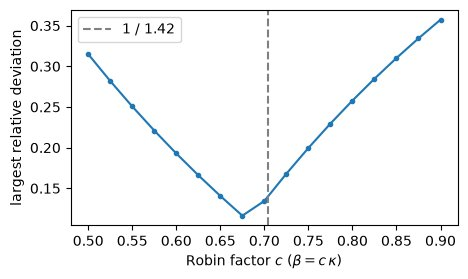

best factor 0.675 (largest deviation 11.6%); 1/1.42 = 0.704


In [5]:
probe = ([(x, 0.0) for x in np.linspace(0, 1, 21)] + [(0.0, y) for y in np.linspace(0, 0.5, 11)]
         + [(t, t) for t in np.linspace(0, 0.5, 11)])
factors = np.linspace(0.5, 0.9, 17)
deviation = []
for c in factors:
    g = ngsrng.default_rng(Vm, correlation=ngsrng.matern_correlation(length, nu, boundary="robin", robin=c),
                           dtype="float64").gaussian()
    v = np.diag(ngsrng.functional_covariance(g, points=probe + [(1.0, 0.5)]))
    deviation.append(np.abs(v[:-1] / v[-1] - 1).max())
best = factors[int(np.argmin(deviation))]

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(factors, deviation, ".-")
ax.axvline(1 / 1.42, color="gray", ls="--", label="1 / 1.42")
ax.set_xlabel(r"Robin factor $c$ ($\beta = c\,\kappa$)"), ax.set_ylabel("largest relative deviation")
ax.legend()
plt.show()
print(f"best factor {best:.3f} (largest deviation {min(deviation):.1%}); 1/1.42 = {1 / 1.42:.3f}")

The literature constant is essentially optimal here. Its exact variance map, on the same colour scale as the Neumann
one: within a few percent of 1 almost everywhere. The remaining dip sits in the corners, which no constant $\beta$
can fix (Daon & Stadler's boundary-dependent coefficient, or a pointwise rescaling of the covariance, would). The
faint speckled texture is real, not a plotting artefact: the variance of a finite element field varies by about 1%
within each element, and here that variation crosses a colour band.

variance within 5% of 1 on 94.6% of the domain
variance within 10% of 1 on 99.0% of the domain


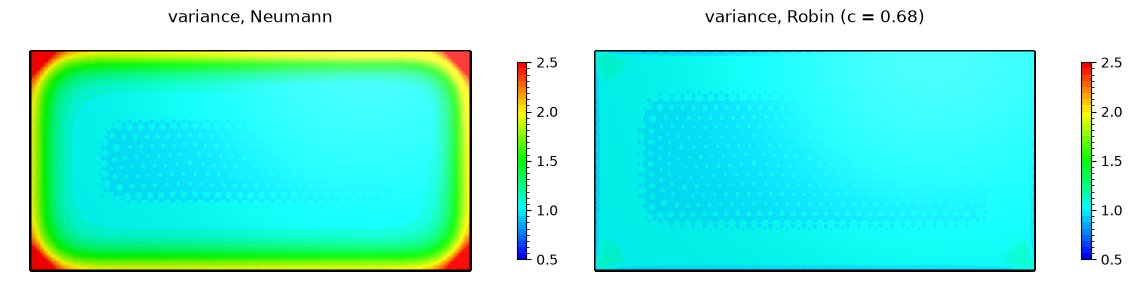

In [6]:
corr = ngsrng.matern_correlation(length, nu, boundary="robin", robin=best)
rng = ngsrng.default_rng(Vm, seed=seed, correlation=corr, dtype="float64")
prior = rng.gaussian()
var_prior = ngsrng.pointwise_variance(prior)
area = ngs.Integrate(1, mesh)
deviation_cf = ngs.IfPos(var_prior - 1, var_prior - 1, 1 - var_prior)
for tol in (0.05, 0.10):
    share = ngs.Integrate(ngs.IfPos(tol - deviation_cf, 1, 0), mesh, order=8) / area
    print(f"variance within {tol:.0%} of 1 on {share:.1%} of the domain")
panels([(var_neumann, dict(vmin=0.5, vmax=2.5)), (var_prior, dict(vmin=0.5, vmax=2.5))],
       ["variance, Neumann", f"variance, Robin (c = {best:.2f})"], mesh=mesh, size=2.6)

Three samples from the prior: the field is equally rough and equally strong everywhere, boundary included.

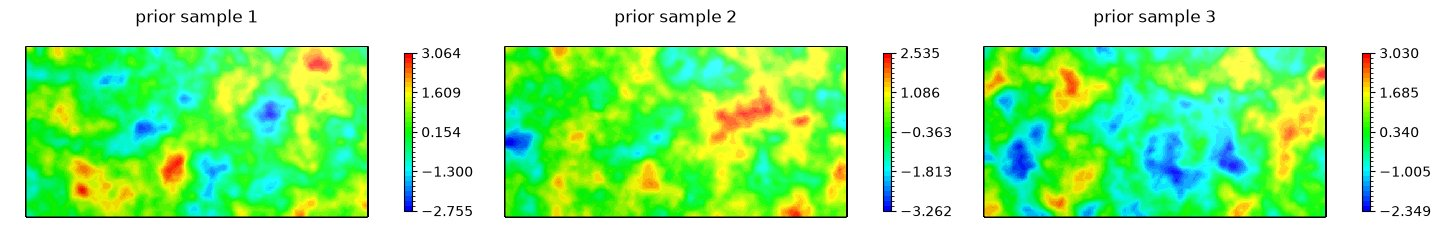

In [7]:
M0 = rng.normal(size=3)
panels([as_gf(M0[k], Vm) for k in range(3)], [f"prior sample {k + 1}" for k in range(3)], ncols=3)

## 4. The forward model: Stokes flow

The weak form: find $(u, p)$ with
$\int 2\,\varepsilon(u):\varepsilon(v) - p\,\nabla\cdot v - q\,\nabla\cdot u \,dx = \int \mathrm{Ra}\, m\, v_y\,dx$
for all $(v, q)$. The left-hand side is assembled and factorised once; the right-hand side is linear in $m$, through
the matrix $B$ of $m \mapsto \int \mathrm{Ra}\, m\, v_y\, dx$.

In [8]:
(ux, uy, p), (vx, vy, q) = Xs.TnT()


def eps(a, b):
    grad = ngs.CF((ngs.grad(a)[0], ngs.grad(a)[1], ngs.grad(b)[0], ngs.grad(b)[1]), dims=(2, 2))
    return 0.5 * (grad + grad.trans)


div_u = ngs.grad(ux)[0] + ngs.grad(uy)[1]
div_v = ngs.grad(vx)[0] + ngs.grad(vy)[1]
K = ngs.BilinearForm(2 * ngs.InnerProduct(eps(ux, uy), eps(vx, vy)) * ngs.dx - (p * div_v + q * div_u) * ngs.dx)
K.Assemble()
K_inv = K.mat.Inverse(Xs.FreeDofs(), "umfpack")

B = ngs.BilinearForm(trialspace=Vm, testspace=Xs)
B += Ra * Vm.TrialFunction() * vy * ngs.dx
B.Assemble()
B = ngsrng.space.to_scipy(B.mat)                                  # (Stokes dofs) x (parameter dofs)


def stokes(m_coefficients):
    # the flow driven by a buoyancy field (coefficient vector)
    sol = ngs.GridFunction(Xs)
    rhs = sol.vec.CreateVector()
    rhs.FV().NumPy()[:] = B @ m_coefficients
    sol.vec.data = K_inv * rhs
    return sol

The "true" buoyancy: a warm (light) blob at depth and a cold (heavy) one near the surface, and the flow it drives.
Drag to rotate and zoom; the arrows show the velocity:

In [9]:
m_true = ngs.GridFunction(Vm)
m_true.Set(ngs.exp(-((ngs.x - 0.6) ** 2 + (ngs.y - 0.35) ** 2) / 0.02)
           - 0.8 * ngs.exp(-((ngs.x - 1.4) ** 2 + (ngs.y - 0.7) ** 2) / 0.03))
flow = stokes(m_true.vec.FV().NumPy())
velocity = ngs.CF((flow.components[0], flow.components[1]))
Draw(velocity, mesh, vectors={"grid_size": 30}, **look);

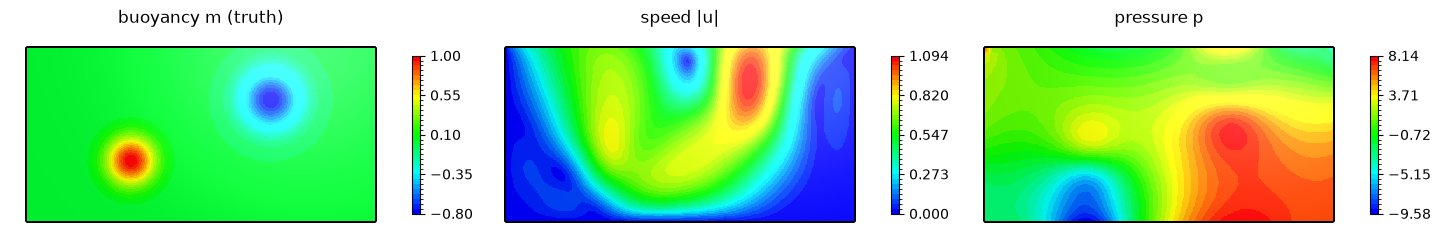

In [10]:
panels([m_true, ngs.Norm(velocity), flow.components[2]], ["buoyancy m (truth)", "speed |u|", "pressure p"], mesh=mesh,
       ncols=3)

**The parameter-to-observable map.** $\mathcal G = O K^{-1} B$, where $O$ takes the velocity components at the
stations. As a matrix it has one row per observation; each row is $\mathcal G^\top e_i = B^\top K^{-1} O^\top e_i$,
one *adjoint* Stokes solve (the Stokes operator is symmetric). `ngsrng.observation_operator(..., adjoint=..., m=...)`
assembles it from that action, so a matrix-free forward model is enough:

In [11]:
work_in, work_out = flow.vec.CreateVector(), flow.vec.CreateVector()


def velocity_operator(points):
    # G for both velocity components at the points, and O (velocity at the points from Stokes coefficients)
    O_x = ngsrng.observation_operator(Vx, points=points)          # point values of one velocity component
    O = sp.bmat([[O_x, None, sp.csr_matrix((len(points), Q.ndof))], [None, O_x, None]]).tocsr()

    def adjoint(Y):
        # G^T Y = B^T K^-1 O^T Y: one adjoint Stokes solve per column
        out = np.empty((Vm.ndof, Y.shape[1]))
        for k in range(Y.shape[1]):
            work_in.FV().NumPy()[:] = O.T @ Y[:, k]
            work_out.data = K_inv * work_in
            out[:, k] = B.T @ work_out.FV().NumPy()
        return out

    return ngsrng.observation_operator(Vm, adjoint=adjoint, m=O.shape[0]), O


stations = np.column_stack([np.linspace(0.05, 1.95, n_stations), np.ones(n_stations)])
t0 = time.time()
G, O = velocity_operator(stations)
d_clean = O @ flow.vec.FV().NumPy()
print(f"G: {G.shape[0]} x {G.shape[1]} in {time.time() - t0:.1f} s; "
      f"|G m - O u| / |O u| = {np.abs(G @ m_true.vec.FV().NumPy() - d_clean).max() / np.abs(d_clean).max():.1e}")

G: 50 x 3841 in 0.5 s; |G m - O u| / |O u| = 4.0e-15


## 5. Synthetic data

The noise standard deviation is `noise_level` times the largest observed velocity. (Generating data with the same
model and mesh used for the inversion is an "inverse crime"; it is fine for a walkthrough, since our point is the
uncertainty, not a realistic error budget.)

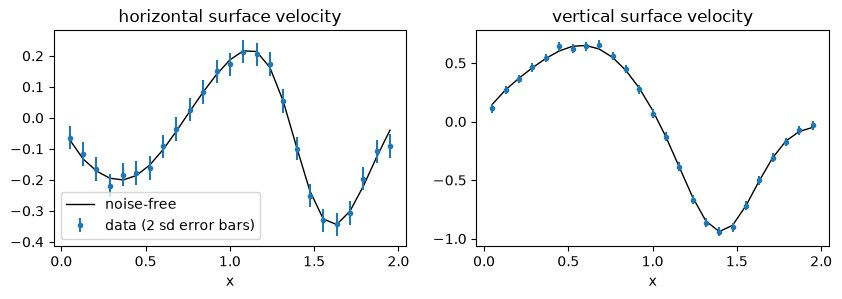

noise standard deviation 0.0188 (2% of the largest velocity)


In [12]:
noise_sd = noise_level * np.abs(d_clean).max()
data = d_clean + noise_sd * np.random.default_rng(seed).standard_normal(d_clean.size)

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharex=True)
for ax, k, name in zip(axes, (0, 1), ("horizontal", "vertical")):
    rows = slice(k * n_stations, (k + 1) * n_stations)
    ax.plot(stations[:, 0], d_clean[rows], "k-", lw=1, label="noise-free")
    ax.errorbar(stations[:, 0], data[rows], yerr=2 * noise_sd, fmt="o", ms=3, label="data (2 sd error bars)")
    ax.set_title(f"{name} surface velocity"), ax.set_xlabel("x")
axes[0].legend()
plt.show()
print(f"noise standard deviation {noise_sd:.3g} ({noise_level:.0%} of the largest velocity)")

## 6. The posterior

`prior.condition(G, noise=..., data=...)` returns the exact posterior as an `ngsrng.Gaussian`: it samples at the cost
of a prior sample plus a low-rank correction. Its mean is the MAP point. Its **variance map is exact** as well: the
prior's (computed above, cached) plus an exact correction of rank at most the number of observations.

posterior and its exact variance map in 2.0 s (prior (exact (all columns)) + exact rank-50 update)


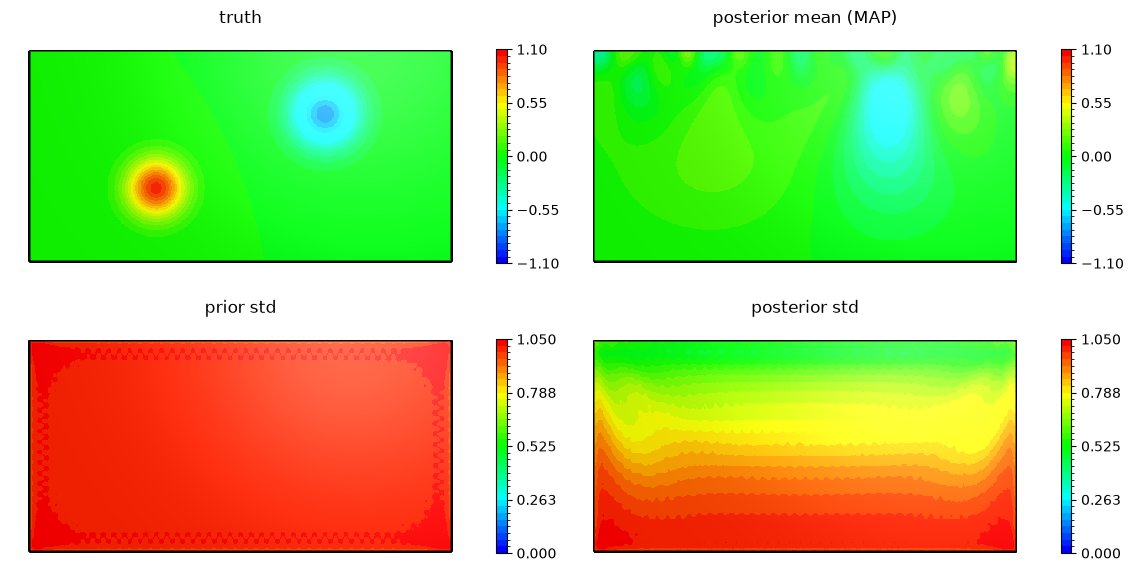

In [13]:
t0 = time.time()
post = prior.condition(G, noise=noise_sd**2, data=data)
m_map = as_gf(post.mean, Vm)
var_post = ngsrng.pointwise_variance(post)
print(f"posterior and its exact variance map in {time.time() - t0:.1f} s "
      f"({ngsrng.local_covariance(post).method})")
std_post = ngs.sqrt(ngs.IfPos(var_post, var_post, 0))
lim = dict(vmin=-1.1, vmax=1.1)
sd_lim = dict(vmin=0, vmax=1.05)
panels([(m_true, lim), (m_map, lim), (ngs.sqrt(var_prior), sd_lim), (std_post, sd_lim)],
       ["truth", "posterior mean (MAP)", "prior std", "posterior std"], ncols=2, mesh=mesh, size=2.6)

The posterior mean finds both anomalies, but smeared and weakened with depth. The posterior standard deviation shows
why: the data pin down the field just below the stations, and the uncertainty returns to the prior's towards the
bottom of the box. In 3D view (`Draw`), the posterior standard deviation:

In [14]:
Draw(std_post, mesh, deformation=True, **look);

Posterior samples: fields consistent with the data. Surface data constrain only the large-scale pattern near the top,
so the samples still vary a lot: at small scales everywhere, and at all scales at depth (compare the posterior
standard deviation above).

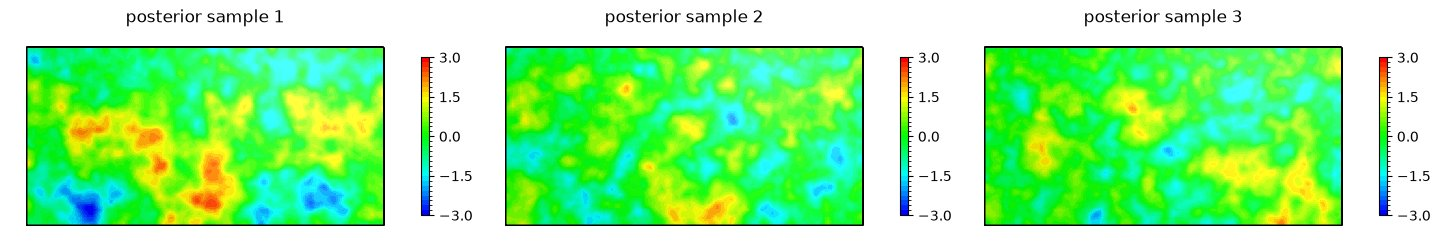

In [15]:
P = post.sample(3).double().numpy().T
panels([(as_gf(P[k], Vm), dict(vmin=-3, vmax=3)) for k in range(3)], [f"posterior sample {k + 1}" for k in range(3)],
       ncols=3)

**Is the uncertainty honest?** The hand-made truth is not a typical prior sample, so it says little about
calibration. The proper check: draw many truths *from the prior*, simulate data for each, and count how often the
truth lies within one and two posterior standard deviations of the posterior mean. The posterior covariance does not
depend on the data, so the factorisation is reused and each truth costs one posterior mean. The standard deviations at
400 random points come exactly from `functional_covariance`:

In [16]:
pts = np.random.default_rng(3).uniform([0.05, 0.05], [1.95, 0.95], (400, 2))
E = ngsrng.observation_operator(Vm, points=pts)                     # point values from coefficients
sd = np.sqrt(np.diag(ngsrng.functional_covariance(post, points=pts)))
obs = ngsrng.LinearObservations(prior, G, noise=noise_sd**2)       # factorised once
truths = prior.sample(50).double().numpy()                          # (ndof x 50) truths drawn from the prior
noise_rng = np.random.default_rng(5)
z = np.concatenate([E @ (obs.posterior(data=G @ t + noise_sd * noise_rng.standard_normal(G.shape[0])).mean - t) / sd
                    for t in truths.T])
for k, ref in ((1, 68.3), (2, 95.4)):
    print(f"truth within {k} posterior sd: {np.mean(np.abs(z) < k):.1%} (Gaussian: {ref}%)")

truth within 1 posterior sd: 68.7% (Gaussian: 68.3%)
truth within 2 posterior sd: 95.7% (Gaussian: 95.4%)


## 7. Checking the fit: posterior predictive

The posterior predictive distribution of the data is Gaussian with covariance
$\mathcal G\,\mathcal C_{\rm post}\,\mathcal G^* + \sigma_n^2 I$; `functional_covariance(post, G)` gives the first term
exactly. The data should scatter around the predictive mean within the bands:

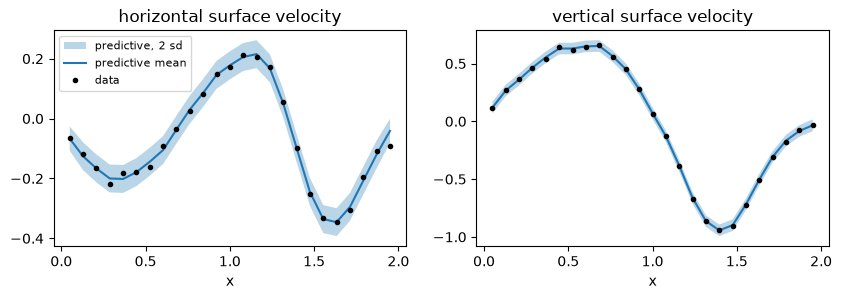

data misfit chi^2 = 14.8 for 50 observations; expected about 17.5 (observations minus the effective number of fitted parameters, sum of lambda / (1 + lambda), see section 8)


In [17]:
pred_mean = G @ post.mean
pred_sd = np.sqrt(np.diag(ngsrng.functional_covariance(post, G)) + noise_sd**2)
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharex=True)
for ax, k, name in zip(axes, (0, 1), ("horizontal", "vertical")):
    rows = slice(k * n_stations, (k + 1) * n_stations)
    xs = stations[:, 0]
    ax.fill_between(xs, pred_mean[rows] - 2 * pred_sd[rows], pred_mean[rows] + 2 * pred_sd[rows], alpha=0.3,
                    label="predictive, 2 sd")
    ax.plot(xs, pred_mean[rows], "-", label="predictive mean")
    ax.plot(xs, data[rows], "k.", label="data")
    ax.set_title(f"{name} surface velocity"), ax.set_xlabel("x")
axes[0].legend(fontsize=8)
plt.show()
chi2 = np.sum(((data - pred_mean) / noise_sd) ** 2)
lam = ngsrng.LinearObservations(prior, G, noise=noise_sd**2).sv ** 2
print(f"data misfit chi^2 = {chi2:.1f} for {data.size} observations; expected about "
      f"{data.size - np.sum(lam / (1 + lam)):.1f} (observations minus the effective number of fitted parameters, "
      f"sum of lambda / (1 + lambda), see section 8)")

## 8. How much do the data tell us?

Write $\mathcal C = LL^*$ and $F = \sigma_n^{-1}\mathcal G L$. The eigenvalues $\lambda_i$ of $F^*F$ (the
*prior-preconditioned data-misfit Hessian*) measure how strongly the data constrain each direction relative to the
prior: directions with $\lambda_i > 1$ are informed by the data, the rest stay at the prior. They also give the
expected information gain, $\tfrac12\sum_i\log(1+\lambda_i)$, and the posterior is the prior with a rank-(number of
observations) update. `ngsrng.LinearObservations` exposes the singular values of $F$ (`.sv`).

Here is how the noise level changes the picture:

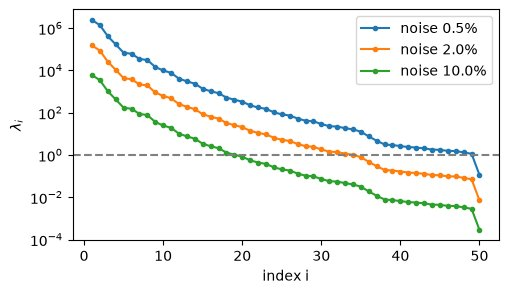

noise   informed directions   information gain (nats)   tr C_post / tr C_prior
 0.5%                    49                     131.7                     0.67
 2.0%                    34                      78.2                     0.68
10.0%                    19                      36.9                     0.70


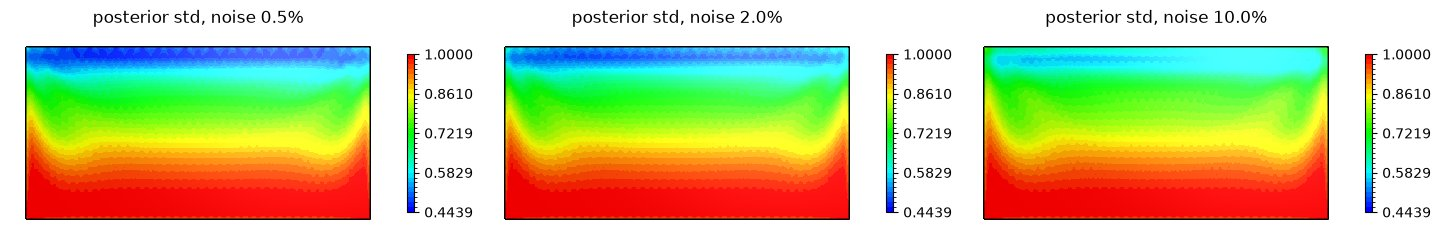

In [18]:
levels = [0.005, 0.02, 0.1]
fig, ax = plt.subplots(figsize=(5.5, 3))
std_maps, rows = [], []
for level in levels:
    sd_n = level * np.abs(d_clean).max()
    obs_level = ngsrng.LinearObservations(prior, G, noise=sd_n**2)
    lam = obs_level.sv**2
    ax.semilogy(np.arange(1, lam.size + 1), lam, ".-", label=f"noise {level:.1%}")
    p = obs_level.posterior()
    v = ngsrng.pointwise_variance(p)
    std_maps.append(ngs.sqrt(ngs.IfPos(v, v, 0)))
    rows.append((level, int((lam > 1).sum()), 0.5 * np.log1p(lam).sum(),
                 ngsrng.covariance_trace(p).value / ngsrng.covariance_trace(prior).value))
ax.axhline(1, color="gray", ls="--")
ax.set_xlabel("index i"), ax.set_ylabel(r"$\lambda_i$"), ax.legend()
plt.show()
print("noise   informed directions   information gain (nats)   tr C_post / tr C_prior")
for level, k, eig, ratio in rows:
    print(f"{level:5.1%}   {k:19d}   {eig:23.1f}   {ratio:22.2f}")
low = min(m(mesh(*x)) for m in std_maps for x in pts)              # common colour range: smallest std at the points
panels([(m, dict(vmin=0.95 * low, vmax=1.0)) for m in std_maps],
       [f"posterior std, noise {level:.1%}" for level in levels], mesh=mesh, ncols=3)

Less noise informs more directions, but each new direction is a smaller-scale or deeper feature with a smaller
eigenvalue: the gain is logarithmic, and the bottom of the box stays uncertain at any noise level.

**Low rank.** A randomised low-rank update (randomised subspace iteration, Aarset 2024, Algorithm 2) replaces the
exact update by one of rank $r$, at the cost of a few applications per direction. How large must $r$ be? The variance
map converges first. The posterior mean needs every direction the data inform, since each carries its own piece of
the signal; for typical truths (drawn from the prior, as in the calibration check) its error drops quickly once $r$
passes the number of informed directions:

In [19]:
informed = int((obs.sv > 1).sum())
print(f"informed directions at noise {noise_level:.1%}: {informed}")
data_t = G @ truths[:, :10] + noise_sd * np.random.default_rng(6).standard_normal((G.shape[0], 10))
exact_means = [obs.posterior(data=d).mean for d in data_t.T]
for rank in sorted({max(informed // 3, 1), max(informed // 2, 1), informed, informed + 10}):
    approx = ngsrng.LinearObservations(prior, G, noise=noise_sd**2, rank=rank)
    v_lr = ngsrng.pointwise_variance(approx.posterior())
    gap = np.sqrt(ngs.Integrate((v_lr - var_post) ** 2, mesh) / ngs.Integrate(var_post**2, mesh))
    mean_gap = np.median([np.linalg.norm(approx.posterior(data=d).mean - m) / np.linalg.norm(m)
                          for d, m in zip(data_t.T, exact_means)])
    print(f"rank {rank:2d}: relative error of the variance map {gap:.1e}, of the posterior mean {mean_gap:.1e}")

informed directions at noise 2.0%: 34


rank 11: relative error of the variance map 1.3e-01, of the posterior mean 5.9e-01


rank 17: relative error of the variance map 5.8e-02, of the posterior mean 4.6e-01


rank 34: relative error of the variance map 4.2e-03, of the posterior mean 1.4e-01


rank 44: relative error of the variance map 3.8e-04, of the posterior mean 5.0e-02


A truth that is rough by the prior's standards, like our hand-made blobs, puts more weight on weakly informed
directions, and its posterior mean needs a higher rank still.

## 9. Where to measure

Surface data leave the depth uncertain. Is it better to double the number of surface stations, or to drill one
vertical borehole with 8 velocity sensors? Each design is a different observation operator; everything else stays the
same. Two standard criteria are cheap to compare: the trace of the posterior covariance (A-optimality: the expected
squared $L^2$ error of the posterior mean) and the expected information gain (D-optimality):

design                           tr C_post / tr C_prior   information gain (nats)


25 surface stations                               0.677                      78.2


50 surface stations                               0.675                      90.8


25 stations + borehole                            0.598                      98.2


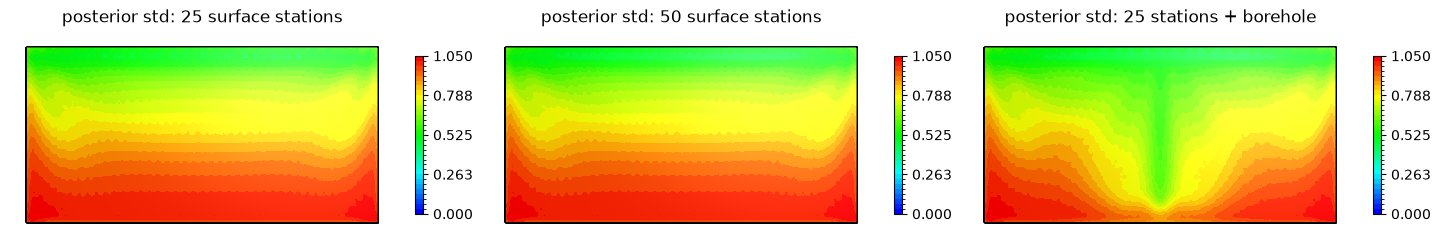

In [20]:
borehole = np.column_stack([np.full(8, 1.0), np.linspace(0.15, 0.85, 8)])
designs = {
    f"{n_stations} surface stations": G,
    f"{2 * n_stations} surface stations": velocity_operator(
        np.column_stack([np.linspace(0.05, 1.95, 2 * n_stations), np.ones(2 * n_stations)]))[0],
    f"{n_stations} stations + borehole": sp.vstack([G, velocity_operator(borehole)[0]]).tocsr(),
}
tr_prior = ngsrng.covariance_trace(prior).value
maps = []
print(f"{'design':32s} tr C_post / tr C_prior   information gain (nats)")
for name, op in designs.items():
    obs_d = ngsrng.LinearObservations(prior, op, noise=noise_sd**2)
    p = obs_d.posterior()
    v = ngsrng.pointwise_variance(p)
    maps.append((ngs.sqrt(ngs.IfPos(v, v, 0)), dict(vmin=0, vmax=1.05)))
    print(f"{name:32s} {ngsrng.covariance_trace(p).value / tr_prior:22.3f}   {0.5 * np.log1p(obs_d.sv**2).sum():23.1f}")
panels(maps, [f"posterior std: {name}" for name in designs], mesh=mesh, ncols=3)

Choosing designs systematically (optimal experimental design) builds on exactly these quantities; it is outside
`ngsrng` itself.

## 10. Cross-check with an independent sampler

Pathwise (Matheron) conditioning samples the same posterior by a different route: draw from the prior, draw noise,
and correct by the data misfit. Its sample standard deviation at the test points should match the exact one up to
Monte Carlo error ($\approx 1/\sqrt{2n}$ relative, about 2% for 1000 samples):

In [21]:
matheron = ngsrng.MatheronPosterior(ngsrng.LinearObservations(prior, G, noise=noise_sd**2, factorize=False),
                                    data=data, seed=7)
S = matheron.sample(1000).numpy()                                  # (ndof x 1000)
sample_sd = (E @ S).std(axis=1)
print(f"posterior mean: largest difference {np.abs(matheron.mean - post.mean).max():.1e}")
print(f"posterior sd at the test points: median relative difference {np.median(np.abs(sample_sd / sd - 1)):.1%}")

posterior mean: largest difference 2.7e-12
posterior sd at the test points: median relative difference 1.6%


## 11. Summary

* A **Robin boundary condition** with $\beta = \kappa/1.42$ removes the variance inflation of the natural condition:
  the prior has essentially the same variance everywhere (exactly computed, and tuned, with `pointwise_variance` and
  `functional_covariance`).
* The **forward model enters only through its adjoint action**: one adjoint Stokes solve per observation builds
  $\mathcal G$, and `prior.condition` does the rest exactly.
* **Posterior variance maps, traces and predictive covariances are exact** and cheap: the prior's variance plus a
  low-rank correction. No sampling is needed to see what the data determine.
* The **spectrum of the prior-preconditioned Hessian** tells how many directions the data inform; a randomised
  low-rank update with that many directions reproduces the posterior.

Nonlinear forward models, non-Gaussian noise and 3D are the subject of the next walkthrough, [hydraulic_tomography_3d.ipynb](hydraulic_tomography_3d.ipynb).

**References.** Daon & Stadler (2018), *Mitigating the influence of the boundary on PDE-based covariance operators*,
Inverse Problems and Imaging 12; Villa & O'Leary-Roseberry (2024), *A note on the relationship between PDE-based
precision operators and Matérn covariances*, arXiv:2407.00471; Roininen, Huttunen & Lasanen (2014), *Whittle–Matérn
priors for Bayesian statistical inversion with applications in electrical impedance tomography*, Inverse Problems and
Imaging 8; Lindgren, Rue & Lindström (2011), JRSS-B 73; Bui-Thanh, Ghattas, Martin & Stadler (2013), SISC 35;
Wilson et al. (2021), JMLR 22 (pathwise conditioning); Aarset (2024), arXiv:2410.16590.